In [1]:
%reload_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings('ignore')
from IPython.display import clear_output

import os, sys
import numpy as np
import pandas as pd
import swifter
import time
from tqdm.auto import tqdm
from rdkit.Chem import BRICS

from rdkit import Chem
from rdkit.Chem import PandasTools
PandasTools.RenderImagesInAllDataFrames(images=True)
from rdkit import RDLogger; RDLogger.DisableLog('rdApp.*')

from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.ipython_useSVG = True
IPythonConsole.molSize = 600, 400
IPythonConsole.drawOptions.addAtomIndices = False

sys.path.append(os.path.abspath(".."))
from new_geass import Geass
clear_output()

In [2]:
df_NPA = pd.read_csv('../data/NPAtlas_download_2024_09.tsv', sep='\t')
df_NPA = df_NPA[~df_NPA['compound_smiles'].str.contains(R'\.')].reset_index(drop=True)
df_NPA = df_NPA[['npaid', 'compound_smiles']].rename(
    columns={'npaid': 'ID', 'compound_smiles': 'ISOSMILES'})
PandasTools.AddMoleculeColumnToFrame(df_NPA, smilesCol='ISOSMILES')

## Wall time calculation

In [ ]:
checkpoints = [100, 200, 400, 1000, 2000, 5000, 10000]
df_samples = df_NPA.sample(10200).reset_index(drop=True)

geass = Geass()
start_total = time.perf_counter()
count = 0

results = []
for mol in df_samples['ROMol'].tolist():
    try:
        geass.get_fragments(mol)
        count += 1
    except Exception:
        continue

    if count in checkpoints:
        elapsed = time.perf_counter() - start_total
        results.append({'n_molecules': count, 'total_time_s': elapsed})
        mol_per_s = count / elapsed
        print(f"{count} molecules processed → {mol_per_s:.2f} mol/s")

df_results = pd.DataFrame(results)
df_results.to_csv('geass_walltime.csv', index=False)

In [ ]:
import plotly.graph_objects as go
import numpy as np

# Extract benchmark data
x = df_results['n_molecules'].values
y = df_results['total_time_s'].values

# --- Amdahl's law ---
p = 0; n_cores = 8
speedup = 1 / ((1 - p) + p / n_cores)
baseline_time = y[0]
x_smooth = np.linspace(x.min(), x.max(), 300)
ideal_times = baseline_time * (x_smooth / x[0]) / speedup

fig = go.Figure()
fig.add_trace(go.Scatter(
    x=x, y=y,
    mode='markers',
    marker=dict(size=8, color="#0D4A70", symbol='diamond')))

fig.add_trace(go.Scatter(
    x=x_smooth,
    y=ideal_times,
    mode='lines',
    name=f'Ideal (Amdahl, p={p}, {n_cores} cores)',
    line=dict(color='black', width=1)))

fig.update_xaxes(
    range=[0, 10500],
    ticktext=[str(i) for i in range(0, 13, 2)],
    tickvals=[i*1000 for i in range(0, 13, 2)],
    tick0=0,           # starting tick
    dtick=2000,        # step size in axis units (2 × 10^3)
    ticks="inside",    # show tick lines inside
    showline=True,
    mirror=True,
    linecolor='black',
    title='Number of molecules × 10<sup>3</sup>',
    title_font=dict(size=17),
    )

# Major ticks for labels
major_ticks = [1e0, 1e1, 1e2, 1e3, 1e4, 1e5]
major_labels = ["10<sup>0</sup>", "10<sup>1</sup>", "10<sup>2</sup>",
                "10<sup>3</sup>", "10<sup>4</sup>", "10<sup>5</sup>"]

# Minor ticks: 2–9 times each power of 10
minor_ticks = []
for i in range(0, 5):
    minor_ticks.extend([j*10**i for j in range(2, 10)])

fig.update_yaxes(
    type='log',
    range=[1, 3.6],
    tickvals=major_ticks,
    ticktext=major_labels,
    ticklen=8,
    showline=True,
    mirror=True,
    showgrid=True,
    gridcolor='lightgrey',
    ticks="inside",
    linecolor='black',
    title='Wall time (s)',
    title_font=dict(size=17),
    minor=dict(
        tickvals=minor_ticks,
        ticks="inside",
        ticklen=4,
        showgrid=True,
        gridcolor='lightgrey'))


fig.update_layout(
    width=650, height=430,
    margin=dict(t=30, b=70, l=70, r=40),
    font=dict(family="sans-serif"),
    showlegend=False,
    plot_bgcolor='white',
    paper_bgcolor='white')

fig.show(config={"toImageButtonOptions": {"format": "png", "scale": 5}})

## Method comparsion

In [ ]:
df_sample = df_NPA.sample(2000).reset_index(drop=True)

frags_geass = []
for mol in df_sample['ROMol'].tolist():
    geass = Geass()
    fragments = geass.get_fragments(mol)
    frags_geass.append(fragments)

df_sample['Frag_Geass'] = frags_geass

df_sample = df_sample[df_sample['Frag_Geass_IDs'].swifter.apply(lambda x: len(x) > 1)].reset_index(drop=True).head(1000)
df_sample.to_pickle('geass_fragments_1000.pkl')

In [160]:
df_geass = pd.read_pickle('geass_fragments_1000.pkl')

start_total = time.perf_counter()

frags_geass = []
for mol in df_geass['ROMol'].tolist():
    geass = Geass()
    fragments = geass.get_fragments(mol, annotate=False)
    frags_geass.append(fragments)

elapsed = time.perf_counter() - start_total
print(f"{elapsed:.2f} seconds")

df_geass['Frag_Geass'] = frags_geass

#! Elapsed time = 4.00 seconds

3.77 seconds


In [5]:
df_brics = df_geass[['ID', 'ISOSMILES', 'ROMol']].copy()

start_total = time.perf_counter()

frag_brics = []
for mol in df_brics['ROMol'].tolist():
    try:
        fragments = BRICS.BRICSDecompose(mol, returnMols=True)
        frag_brics.append(list(fragments))
    except Exception:
        frag_brics.append([])

elapsed = time.perf_counter() - start_total
print(f"{elapsed:.2f} seconds")

df_brics['Frag_Brics'] = frag_brics

#! Elapsed time = 186.86 seconds

296.10 seconds


In [ ]:
#! 4532.55 seconds
import metadisassembler

df_meta = df_geass[['ID', 'ISOSMILES', 'ROMol']].copy().head(100)

start_total = time.perf_counter()

frag_meta = []
for smi in tqdm(df_meta['ISOSMILES'].tolist()):
    try:
        medi = metadisassembler.MetaDisassembler()
        medi.input_query(smi)
        fragments = medi.disassemble()
        frag_meta.append(fragments)
    except Exception:
        frag_meta.append([])

elapsed = time.perf_counter() - start_total
print(f"{elapsed:.2f} seconds")

df_meta['Inchi_Meta'] = frag_meta
df_meta = df_meta[~df_meta["Inchi_Meta"].apply(lambda x: x == False or (isinstance(x, list) and len(x) == 0))]
df_meta['Frag_Meta'] = df_meta['Inchi_Meta'].apply(lambda row: [Chem.MolFromInchi(x) for x in row])

df_meta.to_pickle('metadi_fragments_100.pkl')

In [ ]:
# ---- compute metrics ----
df_geass['n_frags'] = df_geass['Frag_Geass'].apply(len)
df_geass = df_geass.explode(['Frag_Geass'])
df_geass['n_atoms'] = df_geass['Frag_Geass'].apply(lambda m: m.GetNumAtoms())
df_geass = df_geass[df_geass['n_atoms'] < 200].reset_index(drop=True)

df_brics['n_frags'] = df_brics['Frag_Brics'].apply(len)
df_brics = df_brics.explode(['Frag_Brics'])
df_brics['n_atoms'] = df_brics['Frag_Brics'].apply(lambda m: m.GetNumAtoms())
df_brics = df_brics[df_brics['n_atoms'] < 200].reset_index(drop=True)

df_meta['n_frags'] = df_meta['Frag_Meta'].apply(len)
df_meta = df_meta.explode(['Frag_Meta'])
df_meta['n_atoms'] = df_meta['Frag_Meta'].apply(lambda m: m.GetNumAtoms())
df_meta = df_meta[df_meta['n_atoms'] < 200].reset_index(drop=True)

In [ ]:
import numpy as np
import pandas as pd

pairs = df_meta[["n_frags", "n_atoms"]].to_numpy()

n_new = 600
syn_pairs = pairs[np.random.randint(0, len(pairs), size=n_new)]

# equal treatment for both axes
disc_noise = np.random.randint(-3, 4, size=syn_pairs.shape)
cont_noise = np.random.normal(scale=2.0, size=syn_pairs.shape)

syn_vals = syn_pairs + disc_noise + cont_noise
syn_vals = np.clip(syn_vals, a_min=1, a_max=None).astype(int)

df_syn = pd.DataFrame(syn_vals, columns=["n_frags", "n_atoms"])

# equal outliers for both axes
n_out = 5
max_vals = df_meta[["n_frags", "n_atoms"]].max().to_numpy()
low = max_vals * 1
high = max_vals * 2

outliers = np.vstack([
    np.random.randint(low[i], high[i], size=n_out)
    for i in range(2)
]).T

df_out = pd.DataFrame(outliers, columns=["n_frags", "n_atoms"])

df_syn = pd.concat([df_syn, df_out], ignore_index=True)


In [213]:
df_plot = pd.concat([
    pd.DataFrame({"method": "GEASS", "n_atoms": df_geass["n_atoms"]}),
    pd.DataFrame({"method": "BRICS", "n_atoms": df_brics["n_atoms"]}),
    pd.DataFrame({"method": "META", "n_atoms": df_syn["n_atoms"]})
], ignore_index=True)

In [226]:
import plotly.graph_objects as go

fig = go.Figure()
datasets = [("BRICS", df_brics, "#9A273E"),
            ('MetaDi', df_syn, 'yellow'),
            ("GEASS", df_geass, "#1D5E87")]

for name, df, color in datasets:
    fig.add_trace(go.Scatter(
        x=df['n_atoms'],
        y=df['n_frags'],
        mode='markers',
        name=name,
        marker=dict(size=6, color=color)))

for name, df, color in datasets:
    fig.add_trace(go.Box(
        y=df['n_frags'],
        xaxis='x2',
        name=name,
        boxpoints='outliers',
        marker=dict(symbol='circle-open', size=6),
        # hoverinfo='skip',
        showlegend=False,
        line=dict(color=color)))

for name, df, color in datasets:
    fig.add_trace(go.Box(
        x=df['n_atoms'],
        yaxis='y2',
        name=name,
        boxpoints='outliers',
        marker=dict(symbol='circle-open', size=6),
        # hoverinfo='skip',
        showlegend=False,
        line=dict(color=color)))

fig.update_layout(
    width=750, height=550,
    # margin=dict(t=10, b=50, l=70, r=10),

    font=dict(family="sans-serif"),
    showlegend=False,
    plot_bgcolor='white',
    paper_bgcolor='white',


    xaxis=dict(
        # domain=[0, 0.8],
        title='Number of atoms per fragment',
        title_font=dict(size=17),
        showline=True,
        mirror=True,
        linecolor='black',
        ticks="inside",
        range=[0, 150.1],
    ),
    yaxis=dict(
        # domain=[0, 0.8],
        title='Number of fragments per molecule',
        title_font=dict(size=17),
        showline=True,
        mirror=True,
        showgrid=True,
        gridcolor='lightgrey',
        ticks="inside",
        linecolor='black',
        range=[-0.1, 35],),

    xaxis2=dict(  # right boxes
        domain=[0.85, 1]),

    yaxis2=dict(  # top boxes
        domain=[0.78, 1]),
)

fig.show(config={"toImageButtonOptions": {"format": "png", "scale": 5}})

Pandas Apply:   0%|          | 0/4174 [00:00<?, ?it/s]

,ID,ISOSMILES,ROMol,Frag_Geass,Frag_Geass_IDs,n_frags,n_atoms,Annot
0,NPA021052,C1C(C(C(C(C1O)O)OC2C(C(C(O2)CO)O)O)OC3C(C(C(C(...,,,"[~C00121, ~C00329, ~C17580]",3,10,
1,NPA021052,C1C(C(C(C(C1O)O)OC2C(C(C(O2)CO)O)O)OC3C(C(C(C(...,,,"[~C00121, ~C00329, ~C17580]",3,12,
2,NPA021052,C1C(C(C(C(C1O)O)OC2C(C(C(O2)CO)O)O)OC3C(C(C(C(...,,,"[~C00121, ~C00329, ~C17580]",3,11,
3,NPA016311,CCC(C)CC(C)CCCCCCCCC(=O)N[C@H]1C[C@H](CNC(=O)[...,,,"[C05147, ~C00064, ~C18622, C01157, C00188, ~C0...",7,9,
4,NPA016311,CCC(C)CC(C)CCCCCCCCC(=O)N[C@H]1C[C@H](CNC(=O)[...,,,"[C05147, ~C00064, ~C18622, C01157, C00188, ~C0...",7,11,
...,...,...,...,...,...,...,...,...
4170,NPA036325,C=C1[C@@H](C)[C@H]2[C@H](CC3=CC=CC=C3)NC(=O)[C...,,,"[, <C00019>, <C00019>]",3,41,
4171,NPA036325,C=C1[C@@H](C)[C@H]2[C@H](CC3=CC=CC=C3)NC(=O)[C...,,,"[, <C00019>, <C00019>]",3,2,
4172,NPA036325,C=C1[C@@H](C)[C@H]2[C@H](CC3=CC=CC=C3)NC(=O)[C...,,,"[, <C00019>, <C00019>]",3,2,
4173,NPA027024,CCCCC[C@H]1[C@@H]2C(=O)[C@@H](C(=O)OC)[C@@H]3[...,,,"[C00132, ]",2,2,

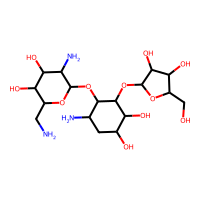
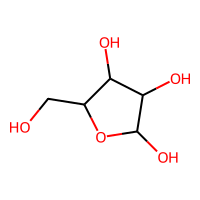
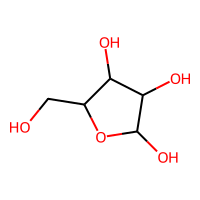
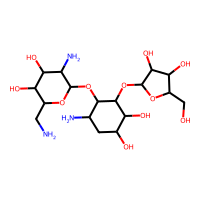
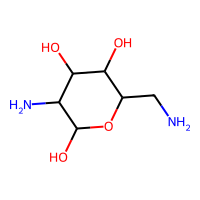
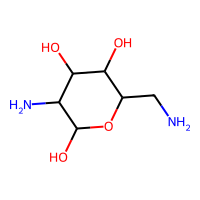
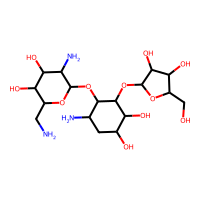
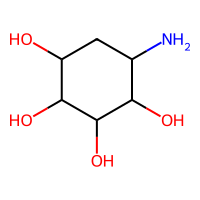
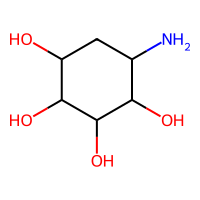
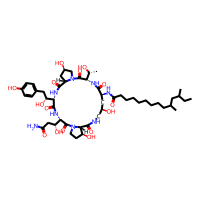
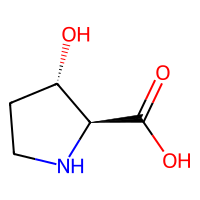
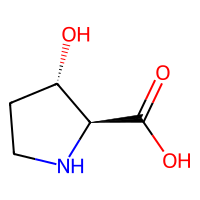
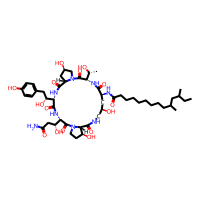
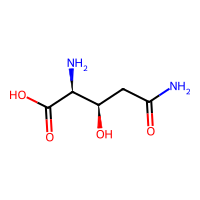
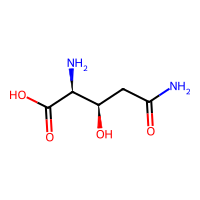
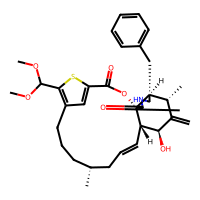
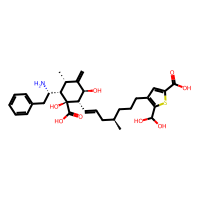
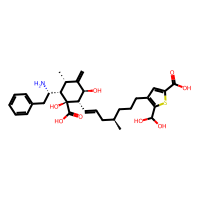
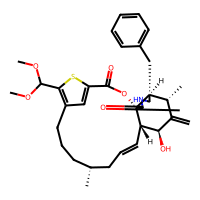
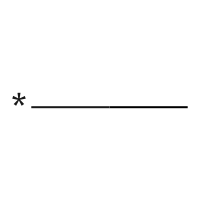
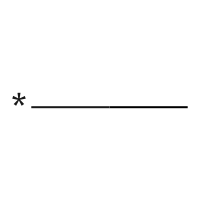
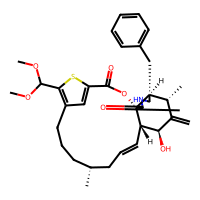
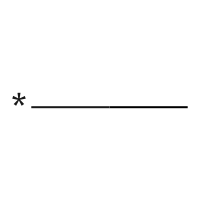
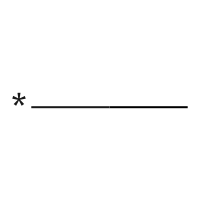
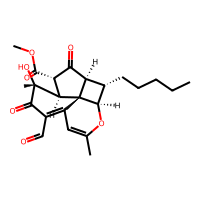
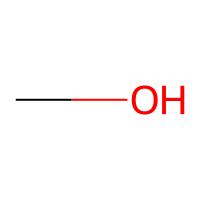
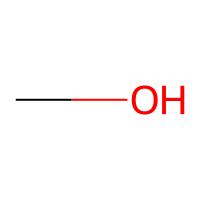
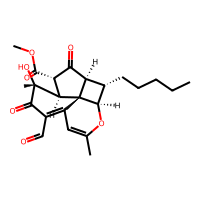
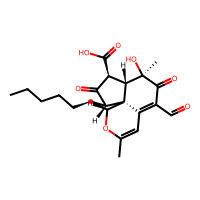
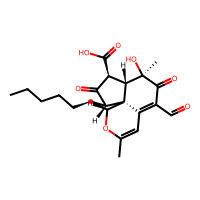

In [229]:
from annotation import AnnotationEngine
annotator = AnnotationEngine()


df_geass['Annot'] = df_geass['Frag_Geass'].swifter.apply(annotator.annotate_fragment)
df_geass